# Analisis Produk dan Pelanggan

# Import Library

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from lifetimes.utils import summary_data_from_transaction_data

# Data Understanding

## Import Dataset dan Sumber, Nama, Format, serta Tujuan Dataset

In [2]:
data = pd.read_csv("Auto Sales data.csv") # Membaca file csv

In [3]:
df = pd.DataFrame(data) # Mengubahnya menjadi DataFrame
df

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,PRODUCTCODE,CUSTOMERNAME,PHONE,ADDRESSLINE1,CITY,POSTALCODE,COUNTRY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,24/02/2018,828,Shipped,Motorcycles,95,S10_1678,Land of Toys Inc.,2125557818,897 Long Airport Avenue,NYC,10022,USA,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,07/05/2018,757,Shipped,Motorcycles,95,S10_1678,Reims Collectables,26.47.1555,59 rue de l'Abbaye,Reims,51100,France,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,01/07/2018,703,Shipped,Motorcycles,95,S10_1678,Lyon Souveniers,+33 1 46 62 7555,27 rue du Colonel Pierre Avia,Paris,75508,France,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,25/08/2018,649,Shipped,Motorcycles,95,S10_1678,Toys4GrownUps.com,6265557265,78934 Hillside Dr.,Pasadena,90003,USA,Young,Julie,Medium
4,10168,36,96.66,1,3479.76,28/10/2018,586,Shipped,Motorcycles,95,S10_1678,Technics Stores Inc.,6505556809,9408 Furth Circle,Burlingame,94217,USA,Hirano,Juri,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2742,10350,20,112.22,15,2244.40,02/12/2019,2924,Shipped,Ships,54,S72_3212,Euro Shopping Channel,(91) 555 94 44,"C/ Moralzarzal, 86",Madrid,28034,Spain,Freyre,Diego,Small
2743,10373,29,137.19,1,3978.51,31/01/2020,2865,Shipped,Ships,54,S72_3212,"Oulu Toy Supplies, Inc.",981-443655,Torikatu 38,Oulu,90110,Finland,Koskitalo,Pirkko,Medium
2744,10386,43,125.99,4,5417.57,01/03/2020,2836,Resolved,Ships,54,S72_3212,Euro Shopping Channel,(91) 555 94 44,"C/ Moralzarzal, 86",Madrid,28034,Spain,Freyre,Diego,Medium
2745,10397,34,62.24,1,2116.16,28/03/2020,2810,Shipped,Ships,54,S72_3212,Alpha Cognac,61.77.6555,1 rue Alsace-Lorraine,Toulouse,31000,France,Roulet,Annette,Small


In [4]:
df.info() # Untuk mengetahui jumlah baris dan kolom. Mengetahui missing value tiap kolom, nama nama kolom, dan tipe data tiap kolom

<class 'pandas.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   ORDERNUMBER           2747 non-null   int64  
 1   QUANTITYORDERED       2747 non-null   int64  
 2   PRICEEACH             2747 non-null   float64
 3   ORDERLINENUMBER       2747 non-null   int64  
 4   SALES                 2747 non-null   float64
 5   ORDERDATE             2747 non-null   str    
 6   DAYS_SINCE_LASTORDER  2747 non-null   int64  
 7   STATUS                2747 non-null   str    
 8   PRODUCTLINE           2747 non-null   str    
 9   MSRP                  2747 non-null   int64  
 10  PRODUCTCODE           2747 non-null   str    
 11  CUSTOMERNAME          2747 non-null   str    
 12  PHONE                 2747 non-null   str    
 13  ADDRESSLINE1          2747 non-null   str    
 14  CITY                  2747 non-null   str    
 15  POSTALCODE            2747 non-n

In [5]:
df.describe() # Untuk mengetahui informasi statistik deskriptif pada kolom dengan tipe data integer dan float

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,DAYS_SINCE_LASTORDER,MSRP
count,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000,2747.000000
mean,10259.761558,35.103021,101.098952,6.491081,3553.047583,1757.085912,100.691664
std,91.877521,9.762135,42.042549,4.230544,1838.953901,819.280576,40.114802
min,10100.000000,6.000000,26.880000,1.000000,482.130000,42.000000,33.000000
25%,10181.000000,27.000000,68.745000,3.000000,2204.350000,1077.000000,68.000000
50%,10264.000000,35.000000,95.550000,6.000000,3184.800000,1761.000000,99.000000
75%,10334.500000,43.000000,127.100000,9.000000,4503.095000,2436.500000,124.000000
max,10425.000000,97.000000,252.870000,18.000000,14082.800000,3562.000000,214.000000


## Data Exploration

### Membuat Copy Dataset

In [6]:
df_copy = df.copy() # Membuat copy dataset

### Cek Inkonsistensi Data

In [7]:
inkonsistensi = df_copy.select_dtypes(include=["str"]).columns

In [8]:
for i in inkonsistensi :
    print(f"Kolom {i} :")
    print(df_copy[i].unique())
    print("\n")

Kolom ORDERDATE :
<ArrowStringArray>
['24/02/2018', '07/05/2018', '01/07/2018', '25/08/2018', '28/10/2018',
 '11/11/2018', '18/11/2018', '15/01/2019', '20/02/2019', '05/04/2019',
 ...
 '29/03/2019', '28/02/2020', '20/04/2019', '02/03/2020', '11/04/2018',
 '13/08/2018', '08/10/2018', '01/12/2018', '28/03/2020', '21/04/2018']
Length: 246, dtype: str


Kolom STATUS :
<ArrowStringArray>
['Shipped', 'Disputed', 'In Process', 'Cancelled', 'On Hold', 'Resolved']
Length: 6, dtype: str


Kolom PRODUCTLINE :
<ArrowStringArray>
[     'Motorcycles',     'Classic Cars', 'Trucks and Buses',
     'Vintage Cars',           'Planes',            'Ships',
           'Trains']
Length: 7, dtype: str


Kolom PRODUCTCODE :
<ArrowStringArray>
[ 'S10_1678',  'S10_1949',  'S10_2016',  'S10_4698',  'S10_4757',  'S10_4962',
  'S12_1099',  'S12_1108',  'S12_1666',  'S12_2823',
 ...
 'S700_2466', 'S700_2610', 'S700_2824', 'S700_2834', 'S700_3167', 'S700_3505',
 'S700_3962', 'S700_4002',  'S72_1253',  'S72_3212']
Le

### Jumlah dan Persentase Missing Value

In [9]:
df_copy_miss = df_copy.isnull().sum() # Mencari jumlah missing value
df_copy_miss_percentage = df_copy_miss / len(df_copy) * 100 # Mencari persentase missing value

In [10]:
print(f"Jumlah missing value : \n{df_copy_miss}")
print(f"Persentase missing value : \n{df_copy_miss_percentage}")

Jumlah missing value : 
ORDERNUMBER             0
QUANTITYORDERED         0
PRICEEACH               0
ORDERLINENUMBER         0
SALES                   0
ORDERDATE               0
DAYS_SINCE_LASTORDER    0
STATUS                  0
PRODUCTLINE             0
MSRP                    0
PRODUCTCODE             0
CUSTOMERNAME            0
PHONE                   0
ADDRESSLINE1            0
CITY                    0
POSTALCODE              0
COUNTRY                 0
CONTACTLASTNAME         0
CONTACTFIRSTNAME        0
DEALSIZE                0
dtype: int64
Persentase missing value : 
ORDERNUMBER             0.0
QUANTITYORDERED         0.0
PRICEEACH               0.0
ORDERLINENUMBER         0.0
SALES                   0.0
ORDERDATE               0.0
DAYS_SINCE_LASTORDER    0.0
STATUS                  0.0
PRODUCTLINE             0.0
MSRP                    0.0
PRODUCTCODE             0.0
CUSTOMERNAME            0.0
PHONE                   0.0
ADDRESSLINE1            0.0
CITY                   

### Jumlah dan Persentase Duplicate Value

In [11]:
duplicate_all = df_copy.duplicated().sum() # Memeriksa jumlah duplicate value berdasarkan tiap baris
persent_duplicate_all = duplicate_all /len(df_copy)*100 # Menghitung persentase duplicate value
print(f"Jumlah Baris yang duplikat = {duplicate_all}")
print(f"Persentase Baris yang duplikat = {persent_duplicate_all:.2f}%")

Jumlah Baris yang duplikat = 0
Persentase Baris yang duplikat = 0.00%


### Encoder Kolom Kategori Untuk Periksa Outlier

In [12]:
from sklearn.preprocessing import LabelEncoder # Memanggil Library untuk LabelEncoder

In [13]:
le = LabelEncoder()

In [14]:
'''Membuat LabelEncoder pada tiap Kolom dengan tipe data string'''
df_copy["ORDERDATE_code"] = le.fit_transform(df_copy["ORDERDATE"])
df_copy["STATUS_code"] = le.fit_transform(df_copy["STATUS"])
df_copy["PRODUCTLINE_code"] = le.fit_transform(df_copy["PRODUCTLINE"])
df_copy["PRODUCTCODE_code"] = le.fit_transform(df_copy["PRODUCTCODE"])
df_copy["CUSTOMERNAME_code"] = le.fit_transform(df_copy["CUSTOMERNAME"])
df_copy["PHONE_code"] = le.fit_transform(df_copy["PHONE"])
df_copy["ADDRESSLINE1_code"] = le.fit_transform(df_copy["ADDRESSLINE1"])
df_copy["CITY_code"] = le.fit_transform(df_copy["CITY"])
df_copy["POSTALCODE_code"] = le.fit_transform(df_copy["POSTALCODE"])
df_copy["COUNTRY_code"] = le.fit_transform(df_copy["COUNTRY"])
df_copy["CONTACTLASTNAME_code"] = le.fit_transform(df_copy["CONTACTLASTNAME"])
df_copy["CONTACTFIRSTNAME_code"] = le.fit_transform(df_copy["CONTACTFIRSTNAME"])
df_copy["DEALSIZE_code"] = le.fit_transform(df_copy["DEALSIZE"])

### Jumlah dan Persentase Outlier Dengan IQR

In [15]:
'''Membuat Variabel Baru Untuk Mengambil Nama Kolom Dengan Tipe Data Numerikal'''
kolom_numerik = df_copy.select_dtypes(include=["float64", "int64"]).columns

In [16]:
kolom_numerik

Index(['ORDERNUMBER', 'QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER',
       'SALES', 'DAYS_SINCE_LASTORDER', 'MSRP', 'ORDERDATE_code',
       'STATUS_code', 'PRODUCTLINE_code', 'PRODUCTCODE_code',
       'CUSTOMERNAME_code', 'PHONE_code', 'ADDRESSLINE1_code', 'CITY_code',
       'POSTALCODE_code', 'COUNTRY_code', 'CONTACTLASTNAME_code',
       'CONTACTFIRSTNAME_code', 'DEALSIZE_code'],
      dtype='str')

In [17]:
for i in kolom_numerik :
    Q1 = df_copy[i].quantile(0.25)
    Q3 = df_copy[i].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outlier = (df_copy[i] < lower) | (df_copy[i] > upper)
    jumlah_outlier = outlier.sum() # Mengetahui jumlah outlier pada kolom
    persentase_outlier = jumlah_outlier/len(outlier) * 100 # Mengetahui persentase outlier pada kolom
    print(f"Jumlah Outlier pada Kolom {i} : {jumlah_outlier}")
    print(f"Persentase Outlier pada Kolom {i} : {persentase_outlier:.2f}%\n")

Jumlah Outlier pada Kolom ORDERNUMBER : 0
Persentase Outlier pada Kolom ORDERNUMBER : 0.00%

Jumlah Outlier pada Kolom QUANTITYORDERED : 8
Persentase Outlier pada Kolom QUANTITYORDERED : 0.29%

Jumlah Outlier pada Kolom PRICEEACH : 33
Persentase Outlier pada Kolom PRICEEACH : 1.20%

Jumlah Outlier pada Kolom ORDERLINENUMBER : 0
Persentase Outlier pada Kolom ORDERLINENUMBER : 0.00%

Jumlah Outlier pada Kolom SALES : 79
Persentase Outlier pada Kolom SALES : 2.88%

Jumlah Outlier pada Kolom DAYS_SINCE_LASTORDER : 0
Persentase Outlier pada Kolom DAYS_SINCE_LASTORDER : 0.00%

Jumlah Outlier pada Kolom MSRP : 26
Persentase Outlier pada Kolom MSRP : 0.95%

Jumlah Outlier pada Kolom ORDERDATE_code : 0
Persentase Outlier pada Kolom ORDERDATE_code : 0.00%

Jumlah Outlier pada Kolom STATUS_code : 206
Persentase Outlier pada Kolom STATUS_code : 7.50%

Jumlah Outlier pada Kolom PRODUCTLINE_code : 0
Persentase Outlier pada Kolom PRODUCTLINE_code : 0.00%

Jumlah Outlier pada Kolom PRODUCTCODE_code : 

### Cek Distribusi Data Dengan Uji Shapiro-Wilk

In [18]:
from scipy.stats import shapiro

In [19]:
for x in kolom_numerik : 
    stat, p = shapiro(df_copy[x])
    print(f"p value Kolom {x} : {p:.3f}")
    if p >= 0.05 :
        print(f"Kolom {x} terdistribusi normal")
    else :
        print(f"Kolom {x} tidak terdistribusi normal\n")

p value Kolom ORDERNUMBER : 0.000
Kolom ORDERNUMBER tidak terdistribusi normal

p value Kolom QUANTITYORDERED : 0.000
Kolom QUANTITYORDERED tidak terdistribusi normal

p value Kolom PRICEEACH : 0.000
Kolom PRICEEACH tidak terdistribusi normal

p value Kolom ORDERLINENUMBER : 0.000
Kolom ORDERLINENUMBER tidak terdistribusi normal

p value Kolom SALES : 0.000
Kolom SALES tidak terdistribusi normal

p value Kolom DAYS_SINCE_LASTORDER : 0.000
Kolom DAYS_SINCE_LASTORDER tidak terdistribusi normal

p value Kolom MSRP : 0.000
Kolom MSRP tidak terdistribusi normal

p value Kolom ORDERDATE_code : 0.000
Kolom ORDERDATE_code tidak terdistribusi normal

p value Kolom STATUS_code : 0.000
Kolom STATUS_code tidak terdistribusi normal

p value Kolom PRODUCTLINE_code : 0.000
Kolom PRODUCTLINE_code tidak terdistribusi normal

p value Kolom PRODUCTCODE_code : 0.000
Kolom PRODUCTCODE_code tidak terdistribusi normal

p value Kolom CUSTOMERNAME_code : 0.000
Kolom CUSTOMERNAME_code tidak terdistribusi normal

### Insight Berdasarkan Hasil Eksplorasi

# Data Preparation

## Data Cleaning

### Menangani Tipe Data

In [20]:
df_copy["ORDERDATE"] = pd.to_datetime(df_copy["ORDERDATE"], format="%d/%m/%Y")

In [21]:
df_copy.info() # Memeriksa kembali tipe data

<class 'pandas.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 33 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   ORDERNUMBER            2747 non-null   int64         
 1   QUANTITYORDERED        2747 non-null   int64         
 2   PRICEEACH              2747 non-null   float64       
 3   ORDERLINENUMBER        2747 non-null   int64         
 4   SALES                  2747 non-null   float64       
 5   ORDERDATE              2747 non-null   datetime64[us]
 6   DAYS_SINCE_LASTORDER   2747 non-null   int64         
 7   STATUS                 2747 non-null   str           
 8   PRODUCTLINE            2747 non-null   str           
 9   MSRP                   2747 non-null   int64         
 10  PRODUCTCODE            2747 non-null   str           
 11  CUSTOMERNAME           2747 non-null   str           
 12  PHONE                  2747 non-null   str           
 13  ADDRESSLINE1  

## Feature Engineering

### Membuat RFM (Recency, Frequency, dan Monetary) Untuk Setiap Customer

In [22]:
summary = summary_data_from_transaction_data(
    df,
    customer_id_col = "CUSTOMERNAME",
    datetime_col = "ORDERDATE",
    monetary_value_col = "SALES"
)
summary

C:\Users\AHMAD MALIK\anaconda3\Lib\site-packages\lifetimes\utils.py:287: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  pd.to_datetime(transactions[datetime_col].max(), format=datetime_format).to_period(freq).to_timestamp()
C:\Users\AHMAD MALIK\anaconda3\Lib\site-packages\lifetimes\utils.py:202: UserWarning: Parsing dates in %d/%m/%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  transactions[datetime_col] = pd.to_datetime(transactions[datetime_col], format=datetime_format)


,frequency,recency,T,monetary_value
CUSTOMERNAME,,,,
"AV Stores, Co.",2.0,609.0,805.0,49990.100000
Alpha Cognac,2.0,633.0,697.0,26618.680000
Amica Models & Co.,1.0,23.0,288.0,56078.260000
"Anna's Decorations, Ltd",3.0,545.0,628.0,37401.393333
Atelier graphique,2.0,554.0,742.0,3809.830000
...,...,...,...,...
"Vida Sport, Ltd",1.0,189.0,464.0,67281.010000
Vitachrome Inc.,2.0,664.0,872.0,31618.460000
"Volvo Model Replicas, Co",3.0,605.0,799.0,18718.510000


### Membuat Score R, F, dan M

In [23]:
rfm = summary.copy()

# Skor R, F dan M: nilai lebih tinggi mendapat skor lebih tinggi.
rfm['R_score'] = pd.qcut(rfm['recency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['F_score'] = pd.qcut(rfm['frequency'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm['M_score'] = pd.qcut(rfm['monetary_value'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

In [24]:
rfm

,frequency,recency,T,monetary_value,R_score,F_score,M_score
CUSTOMERNAME,,,,,,,
"AV Stores, Co.",2.0,609.0,805.0,49990.100000,4,2,5
Alpha Cognac,2.0,633.0,697.0,26618.680000,5,2,2
Amica Models & Co.,1.0,23.0,288.0,56078.260000,1,1,5
"Anna's Decorations, Ltd",3.0,545.0,628.0,37401.393333,4,4,4
Atelier graphique,2.0,554.0,742.0,3809.830000,4,2,1
...,...,...,...,...,...,...,...
"Vida Sport, Ltd",1.0,189.0,464.0,67281.010000,1,2,5
Vitachrome Inc.,2.0,664.0,872.0,31618.460000,5,4,3
"Volvo Model Replicas, Co",3.0,605.0,799.0,18718.510000,4,5,1


### Membuat Segmen RFM Berdasarkan Score

In [25]:
def assign_segment(row):
    r, f, m = row['R_score'], row['F_score'], row['M_score']
    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif f >= 4 and r >= 3:
        return 'Loyal Customers'
    elif r >= 4 and f >= 2:
        return 'Potential Loyalists'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    else:
        return 'Hibernating Customers'

In [26]:
rfm['segment'] = rfm.apply(assign_segment, axis=1)

In [27]:
rfm

,frequency,recency,T,monetary_value,R_score,F_score,M_score,segment
CUSTOMERNAME,,,,,,,,
"AV Stores, Co.",2.0,609.0,805.0,49990.100000,4,2,5,Potential Loyalists
Alpha Cognac,2.0,633.0,697.0,26618.680000,5,2,2,Potential Loyalists
Amica Models & Co.,1.0,23.0,288.0,56078.260000,1,1,5,Hibernating Customers
"Anna's Decorations, Ltd",3.0,545.0,628.0,37401.393333,4,4,4,Champions
Atelier graphique,2.0,554.0,742.0,3809.830000,4,2,1,Potential Loyalists
...,...,...,...,...,...,...,...,...
"Vida Sport, Ltd",1.0,189.0,464.0,67281.010000,1,2,5,Hibernating Customers
Vitachrome Inc.,2.0,664.0,872.0,31618.460000,5,4,3,Loyal Customers
"Volvo Model Replicas, Co",3.0,605.0,799.0,18718.510000,4,5,1,Loyal Customers


### Menggabungkan Data Baru Dengan Copy Dataset

In [28]:
df_rfm = df_copy.merge(
    rfm.reset_index(),
    on="CUSTOMERNAME",
    how="left"
)

In [29]:
df_rfm

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,DAYS_SINCE_LASTORDER,STATUS,PRODUCTLINE,MSRP,...,CONTACTFIRSTNAME_code,DEALSIZE_code,frequency,recency,T,monetary_value,R_score,F_score,M_score,segment
0,10107,30,95.70,2,2871.00,2018-02-24,828,Shipped,Motorcycles,95,...,36,2,3.0,629.0,827.0,39570.593333,5,5,4,Champions
1,10121,34,81.35,5,2765.90,2018-05-07,757,Shipped,Motorcycles,95,...,54,2,4.0,693.0,755.0,29017.745000,5,5,3,Loyal Customers
2,10134,41,94.74,2,3884.34,2018-07-01,703,Shipped,Motorcycles,95,...,11,1,2.0,625.0,700.0,26472.730000,5,3,2,Potential Loyalists
3,10145,45,83.26,6,3746.70,2018-08-25,649,Shipped,Motorcycles,95,...,31,1,2.0,505.0,645.0,30144.300000,3,4,3,Loyal Customers
4,10168,36,96.66,1,3479.76,2018-10-28,586,Shipped,Motorcycles,95,...,32,1,3.0,530.0,677.0,39288.956667,3,5,4,Loyal Customers
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2742,10350,20,112.22,15,2244.40,2019-12-02,2924,Shipped,Ships,54,...,13,2,24.0,851.0,851.0,35769.932917,5,5,3,Loyal Customers
2743,10373,29,137.19,1,3978.51,2020-01-31,2865,Shipped,Ships,54,...,56,1,2.0,497.0,618.0,43278.490000,3,4,5,Loyal Customers
2744,10386,43,125.99,4,5417.57,2020-03-01,2836,Resolved,Ships,54,...,13,1,24.0,851.0,851.0,35769.932917,5,5,3,Loyal Customers
2745,10397,34,62.24,1,2116.16,2020-03-28,2810,Shipped,Ships,54,...,5,2,2.0,633.0,697.0,26618.680000,5,2,2,Potential Loyalists


In [30]:
df_rfm.info()

<class 'pandas.DataFrame'>
RangeIndex: 2747 entries, 0 to 2746
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   ORDERNUMBER            2747 non-null   int64         
 1   QUANTITYORDERED        2747 non-null   int64         
 2   PRICEEACH              2747 non-null   float64       
 3   ORDERLINENUMBER        2747 non-null   int64         
 4   SALES                  2747 non-null   float64       
 5   ORDERDATE              2747 non-null   datetime64[us]
 6   DAYS_SINCE_LASTORDER   2747 non-null   int64         
 7   STATUS                 2747 non-null   str           
 8   PRODUCTLINE            2747 non-null   str           
 9   MSRP                   2747 non-null   int64         
 10  PRODUCTCODE            2747 non-null   str           
 11  CUSTOMERNAME           2747 non-null   str           
 12  PHONE                  2747 non-null   str           
 13  ADDRESSLINE1  

In [31]:
df_clean = df_rfm[[
    "ORDERNUMBER", 
    "QUANTITYORDERED", 
    "PRICEEACH", 
    "ORDERLINENUMBER", 
    "SALES",
    "ORDERDATE",
    "DAYS_SINCE_LASTORDER",
    "STATUS",
    "PRODUCTLINE",
    "MSRP",
    "PRODUCTCODE",
    "CUSTOMERNAME",
    "PHONE",
    "ADDRESSLINE1",
    "CITY",
    "POSTALCODE",
    "COUNTRY",
    "CONTACTLASTNAME",
    "CONTACTFIRSTNAME",
    "DEALSIZE",
    "frequency",
    "recency",
    "T",
    "monetary_value",
    "R_score",
    "F_score",
    "M_score",
    "segment"
]]

In [32]:
df_clean["Bulan"] = df_clean["ORDERDATE"].dt.month

# EDA (Analisa Data)

## Analisis Univariat

### Distribusi Setiap Kolom Numerik

In [33]:
numerik = df_clean.select_dtypes(include=("float64", "int64"))

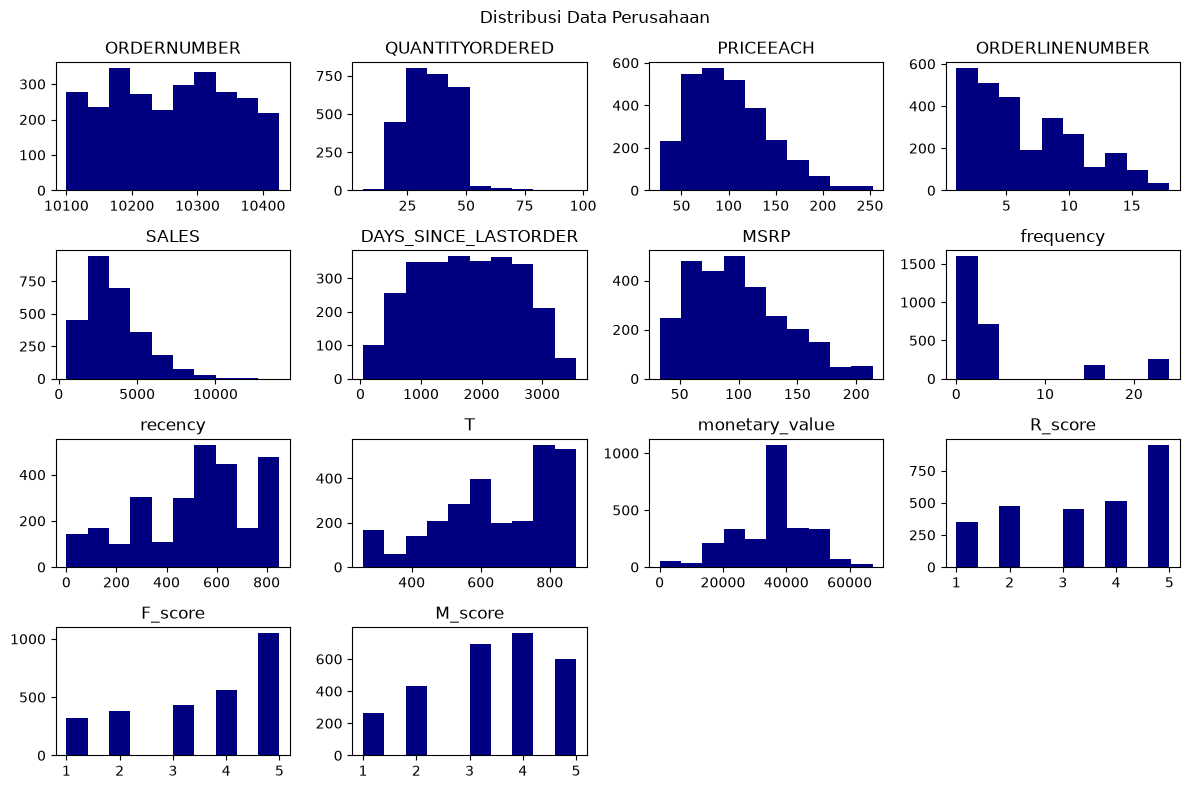

In [34]:
numerik.hist(color='navy', figsize=(12,8), grid=False)
plt.suptitle("Distribusi Data Perusahaan")
plt.tight_layout()
plt.show()

### Segmentasi

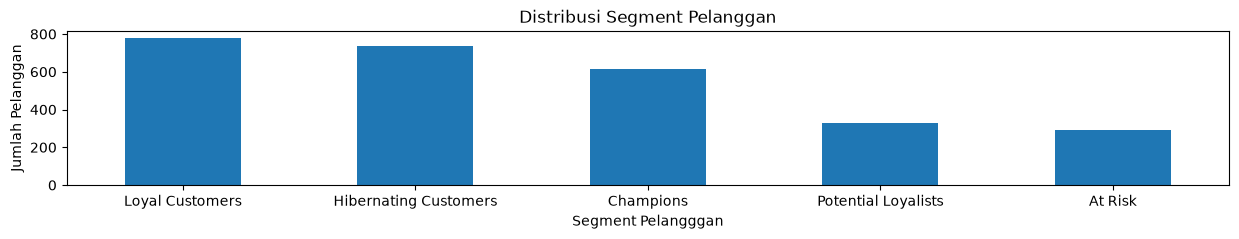

In [35]:
plt.figure(figsize=(15,2))
df_clean["segment"].value_counts().plot(kind="bar")
plt.title("Distribusi Segment Pelanggan")
plt.xlabel("Segment Pelangggan")
plt.ylabel("Jumlah Pelanggan")
plt.xticks(rotation=0)
plt.show()

## Analisis Bivariat

### Heatmap

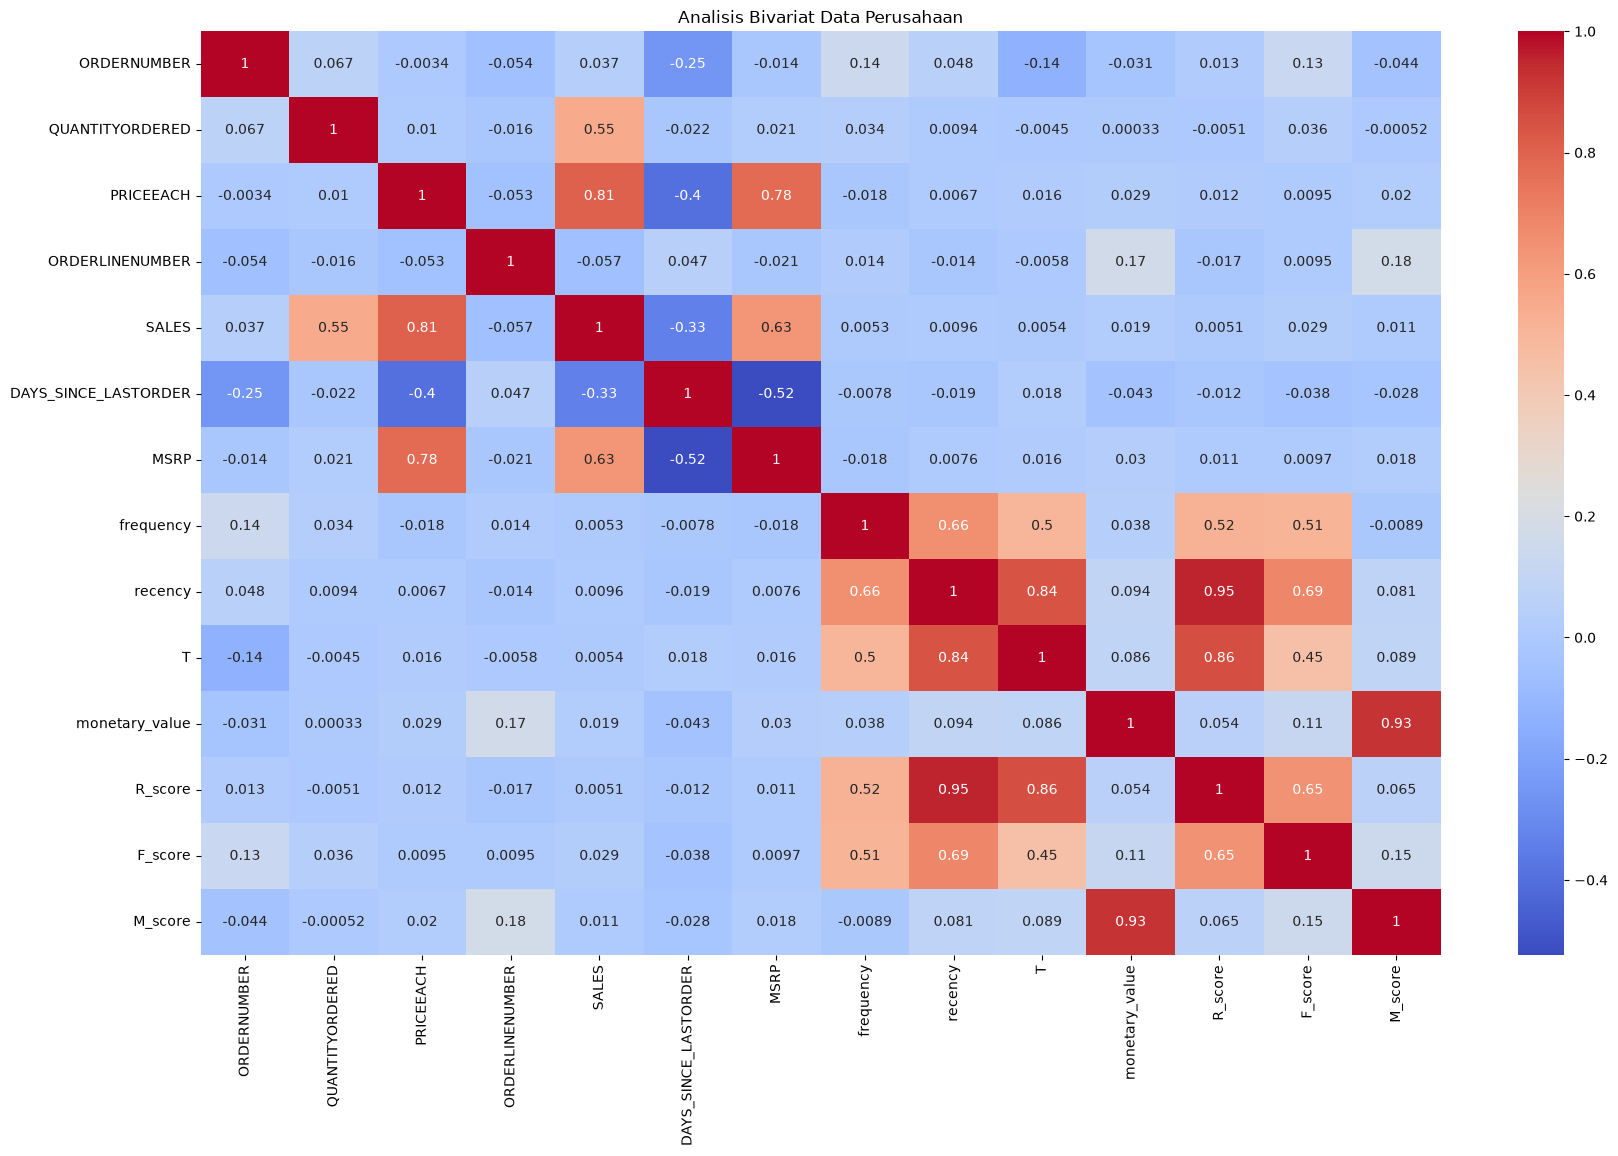

In [36]:
df_corr = numerik.corr()
plt.figure(figsize=(20, 12))
sns.heatmap(
    df_corr,
    annot=True,
    cmap="coolwarm"
)
plt.title("Analisis Bivariat Data Perusahaan")
plt.show()

### Trend Sales Bulanan

In [37]:
bulanan = df_clean.groupby("Bulan").agg(
    sales = ("SALES", "sum")
).reset_index()
bulanan

,Bulan,sales
0,1,761985.12
1,2,756238.28
2,3,735805.81
3,4,669390.96
4,5,923972.56
5,6,454756.78
6,7,514875.97
7,8,659310.57
8,9,584724.27
9,10,1001377.20


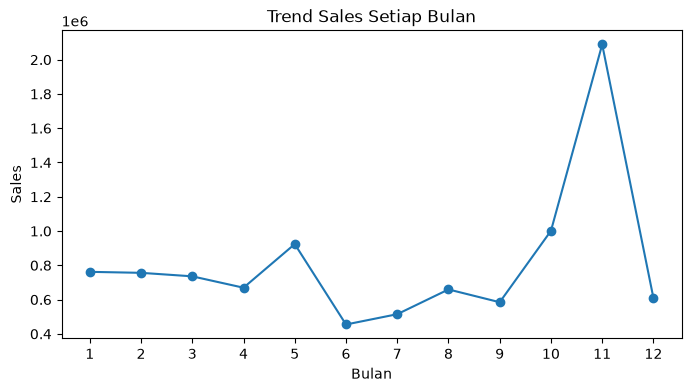

In [38]:
plt.figure(figsize=(8, 4))
plt.plot(bulanan["Bulan"], bulanan["sales"], marker="o")
plt.xticks(bulanan["Bulan"])
plt.title("Trend Sales Setiap Bulan")
plt.xlabel("Bulan")
plt.ylabel("Sales")
plt.show()

Sales paling besar terjadi di bulan November, sehingga disarankan untuk menganalisis bulan November lebih lanjut

### Segmentasi Berdasarkan SALES

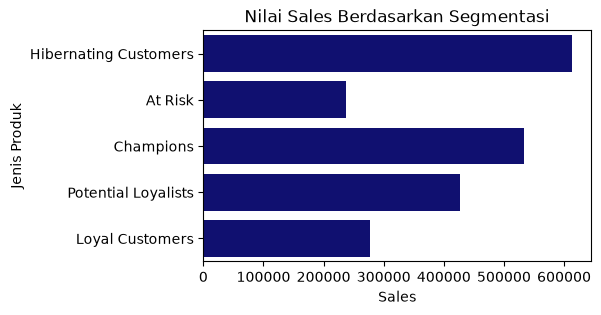

In [39]:
plt.figure(figsize=(5,3))
sns.barplot(
    data = df_clean[df_clean["Bulan"]==11],
    x="SALES",
    y="segment",
    estimator=sum,
    errorbar = ("ci", False),
    color="navy"
)
plt.title("Nilai Sales Berdasarkan Segmentasi")
plt.xlabel("Sales")
plt.ylabel("Jenis Produk")
plt.show()

### Produk Berdasarkan SALES

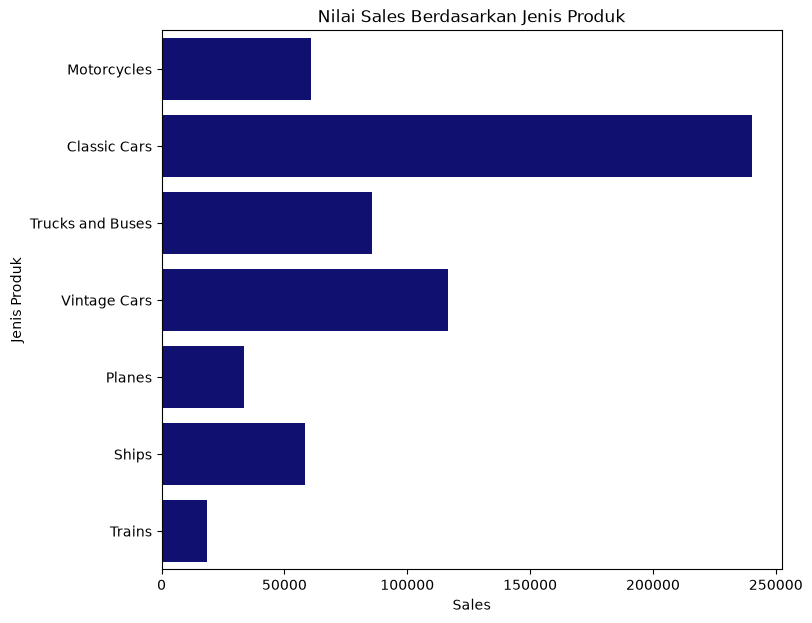

In [40]:
plt.figure(figsize=(8,7))
sns.barplot(
    data = df_clean[(df_clean["Bulan"]==11)&(df_clean["segment"] == "Hibernating Customers")],
    x="SALES",
    y="PRODUCTLINE",
    estimator=sum,
    errorbar = ("ci", False),
    color="navy"
)
plt.title("Nilai Sales Berdasarkan Jenis Produk")
plt.xlabel("Sales")
plt.ylabel("Jenis Produk")
plt.show()

## Analisis Multivariat

# Hubungan segment, PRODUCTLINE, dan SALES

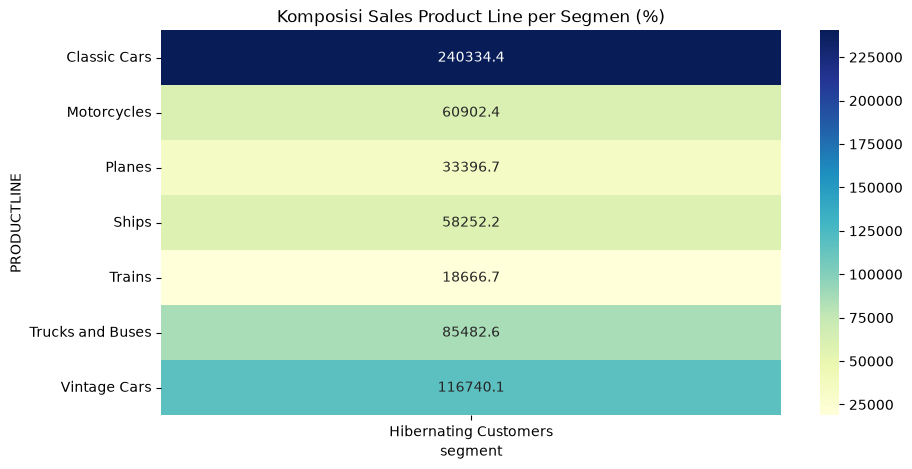

In [41]:
pl_segmen = df_clean[(df_clean["Bulan"]==11)&(df_clean["segment"] == "Hibernating Customers")].pivot_table(index="PRODUCTLINE", columns="segment", values="SALES", aggfunc="sum")
plt.figure(figsize=(10, 5))
sns.heatmap(pl_segmen, annot=True, fmt=".1f", cmap="YlGnBu")
plt.title("Komposisi Sales Product Line per Segmen (%)")
plt.show()

# Ekstrak Data

In [42]:
df_clean.to_excel("Autosales RFM Clean.xlsx", index=False)